# Hybrid fraud triage
**Team T085 · Section E · Project 26 · Phase 2**

The GMM scores transactions by negative log density. The denoising autoencoder scores them by reconstruction MSE. We combine the two because low density and poor reconstruction describe different ways a transaction can depart from legitimate behavior.

**Holdout status.** The historical test was already inspected in Phase 1. The hybrid reference, weights and cutoffs come from validation. The historical test provides a descriptive check of the resulting policy.

## Mapping the two scores to the same scale
For model $j$, transform raw score $s$ to its smoothed empirical tail surprise among the $N_0$ legitimate validation transactions.

$$t_j(s)=-\log\!\left(\frac{1+\#\{i : y_i=0,\ s_{ij}\geq s\}}{N_0+1}\right)$$

Then score each transaction by $(1-w)t_{\mathrm{GMM}} + w\,t_{\mathrm{AE}}$. The smoothing keeps the score finite and caps the influence of any single extreme raw score. Extreme scores can tie when they exceed the reference range.

We compare autoencoder weights **0.05, 0.10, 0.20, 0.35 and 0.50** by mixed-validation AP. Ties favor the smaller weight. The frozen standalone scores serve as component-removal baselines.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'run_phase2_hybrid.py').is_file())
out = root / 'results/phase2/hybrid'
meta = json.loads((out / 'metadata.json').read_text())
weights = pd.read_csv(out / 'validation_weights.csv')
best = weights.sort_values(['validation_ap', 'ae_weight'], ascending=[False, True]).iloc[0]
assert best.ae_weight == meta['ae_weight']
print(f"Selected weights: GMM {meta['gmm_weight']:.0%}, autoencoder {meta['ae_weight']:.0%}")
display(weights.round(4))

Selected weights: GMM 95%, autoencoder 5%


,ae_weight,gmm_weight,validation_ap
0,0.05,0.95,0.6327
1,0.10,0.90,0.6289
2,0.20,0.80,0.5941
3,0.35,0.65,0.4712
4,0.50,0.50,0.3263


## Hybrid and standalone ranking
All three scores use the same validation and historical-test rows. Compare average precision (AP), trapezoidal PR AUC and ROC AUC.

,model,split,average_precision,pr_auc_trapezoidal,roc_auc,base_rate
0,GMM,validation,0.629867,0.628444,0.940519,0.001001
1,GMM,test,0.582203,0.578669,0.918662,0.001317
2,Autoencoder,validation,0.037972,0.036845,0.942111,0.001001
3,Autoencoder,test,0.090755,0.088488,0.931869,0.001317
4,Hybrid,validation,0.632668,0.631366,0.941756,0.001001
5,Hybrid,test,0.575386,0.565239,0.920815,0.001317


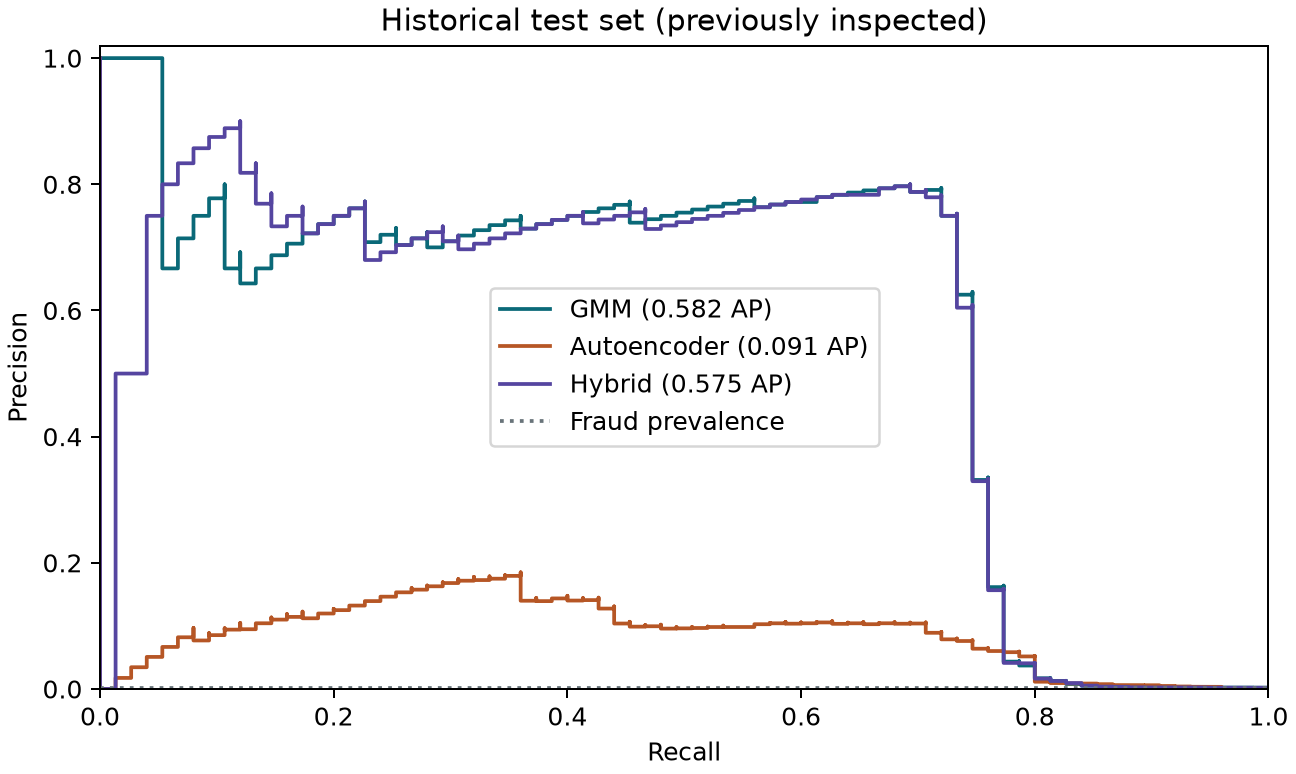

In [2]:
ranking = pd.read_csv(out / 'ranking.csv')
display(ranking.round(6))
display(Image(filename=str(out / 'test_pr_hybrid.png'), width=680))

## Fixed review workload
Each model gets the same number of historical-test reviews. Compare the count and precision of the fraud alerts.

In [3]:
capacity = pd.read_csv(out / 'capacity.csv').query("split == 'test'")
display(capacity.pivot(index='k', columns='model', values=['tp', 'precision_at_k']).round(4))

tp              precision_at_k                
model Autoencoder   GMM Hybrid    Autoencoder     GMM  Hybrid
k                                                            
56            0.0  43.0   43.0         0.0000  0.7679  0.7679
100          11.0  56.0   56.0         0.1100  0.5600  0.5600
284          33.0  57.0   57.0         0.1162  0.2007  0.2007
569          53.0  58.0   58.0         0.0931  0.1019  0.1019

## Validation-calibrated thresholds
Calibrate each score's cutoff using legitimate validation scores. Apply the same cutoff to the historical test. The table distinguishes the nominal validation FPR budget from the realized test FPR.

In [4]:
points = pd.read_csv(out / 'operating_points.csv').query("split == 'test'").copy()
for rate in ['fpr_budget', 'fpr', 'recall', 'precision']:
    points[rate] *= 100
display(points[['fpr_budget', 'model', 'tp', 'fp', 'fpr', 'recall', 'precision']]
        .rename(columns={'fpr_budget': 'Validation budget (%)', 'tp': 'Fraud caught',
                         'fp': 'False alerts', 'fpr': 'Test FPR (%)', 'recall': 'Recall (%)',
                         'precision': 'Precision (%)'})
        .sort_values(['Validation budget (%)', 'model']).round(3).reset_index(drop=True))

,Validation budget (%),model,Fraud caught,False alerts,Test FPR (%),Recall (%),Precision (%)
0,0.1,Autoencoder,0,26,0.046,0.000,0.000
1,0.1,GMM,55,29,0.051,73.333,65.476
2,0.1,Hybrid,55,28,0.049,73.333,66.265
3,0.5,Autoencoder,27,135,0.237,36.000,16.667
4,0.5,GMM,57,175,0.308,76.000,24.569
5,0.5,Hybrid,57,178,0.313,76.000,24.255
6,1.0,Autoencoder,35,314,0.552,46.667,10.029
7,1.0,GMM,58,324,0.570,77.333,15.183
8,1.0,Hybrid,58,320,0.563,77.333,15.344
9,5.0,Autoencoder,60,2169,3.813,80.000,2.692


In [5]:
test_ap = ranking.query("split == 'test'").set_index('model').average_precision
delta = test_ap['Hybrid'] - test_ap['GMM']
ci = meta['historical_paired_ap_difference_ci']
print(f'Historical hybrid-minus-GMM AP: {delta:+.4f}')
print(f"Descriptive 95% paired interval ({ci['replicates']} resamples): "
      f"[{ci['lower']:+.4f}, {ci['upper']:+.4f}]")

Historical hybrid-minus-GMM AP: -0.0068
Descriptive 95% paired interval (300 resamples): [-0.0437, +0.0443]


## What the hybrid adds
Validation AP rises from 0.6299 for GMM to 0.6327 for the hybrid. Historical AP drops from 0.5822 to 0.5754. The hybrid and GMM each catch 57 of 75 frauds in 284 reviews. At the 1% validation budget, both catch 58 frauds and the hybrid produces 320 false alerts versus 324 for GMM. The interval spans zero and conditions on the saved scores and class counts. The small differences do not establish a reliable improvement over GMM.

Run `python run_phase2_hybrid.py --data /path/to/creditcard.csv` with the original ULB/Kaggle CSV to regenerate the outputs. The runner verifies the same chronological split and score row order. This notebook executes using the committed outputs.